# Tahap A2 — Feature Engineering
## Ekstraksi Fitur Hybrid: SWT Haar Level-1 + PHOG pada Subband Aproksimasi A1

**Replikasi Jurnal**:  
> Kar, N.B., Nayak, D.R., Babu, K.S., & Zhang, Y.-D. (2021). *A hybrid feature descriptor with Jaya optimised least squares SVM for facial expression recognition.* **IET Image Processing**, 15(7), 1471–1483. DOI: [10.1049/ipr2.12118](https://doi.org/10.1049/ipr2.12118)

---

### Peran dan Ruang Lingkup A2:
Notebook ini mengimplementasikan tahap **Feature Engineering (A2)** dalam pipeline Facial Expression Recognition (FER):
$$\text{Citra Input (128×128)} \xrightarrow{\text{SWT Haar}} [A_1, H_1, V_1, D_1] \xrightarrow{\text{PHOG}(A_1)} F_{\text{vec}} \in \mathbb{R}^{680}$$

**Deliverables Notebook:**
1. Memuat artefak praproses A1 (`data/ck_preprocessed.npz` dan `data/jaffe_preprocessed.npz`).
2. Landasan teori dan visualisasi 4 subband dekomposisi SWT level-1 ($A_1, H_1, V_1, D_1$).
3. Landasan teori dan visualisasi piramida PHOG ($L=3, K=8, [0 - 360^\circ]$) pada subband $A_1$.
4. Ekstraksi fitur seluruh sampel citra CK+ (981 citra) dan JAFFE (213 citra).
5. Sel verifikasi wajib (`assert F_ck.shape == (981, 680)` dan `assert F_jaffe.shape == (213, 680)`).
6. Analisis statistik fitur (panjang vektor, sparsity, perbandingan lintas ekspresi).
7. Penyimpanan artefak fitur untuk A3 (`data/ck_features.npz` dan `data/jaffe_features.npz`).


## 1. Import Library & Modul Modular A2

Seluruh fungsi logika ekstraksi fitur telah dimodularisasi dalam file `features.py` agar dapat di-import langsung oleh anggota tim lainnya (A3 untuk training/evaluasi dan A4 untuk web API).

In [1]:
import sys
from pathlib import Path
import time

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pywt

# Pastikan root repository dan folder feature-engineering terdaftar di sys.path
curr_dir = Path.cwd()
repo_root = curr_dir.parent if curr_dir.name == "feature-engineering" else curr_dir
feat_dir = repo_root / "feature-engineering"

for p in [str(repo_root), str(feat_dir)]:
    if p not in sys.path:
        sys.path.insert(0, p)

from features import swt_haar_level1, compute_gradients, phog, extract_features

print("✓ Berhasil mengimpor library dan modul features.py!")
print(f"  Repo Root: {repo_root}")


✓ Berhasil mengimpor library dan modul features.py!
  Repo Root: C:\Sora Games\personal needs\KULIAH\SEMESTER 5\PCVK\2nd try\TA-PCVK


## 2. Memuat Artefak Praproses A1

Sesuai pembagian tugas, tahap A1 telah menghasilkan citra grayscale 128×128 piksel dengan histogram equalization dalam format `.npz`:
- `data/ck_preprocessed.npz` (981 citra CK+, 7 kelas)
- `data/jaffe_preprocessed.npz` (213 citra JAFFE, 7 kelas)


In [2]:
ck_path = repo_root / "data" / "ck_preprocessed.npz"
jaffe_path = repo_root / "data" / "jaffe_preprocessed.npz"

d_ck = np.load(ck_path)
X_ck, y_ck, subjects_ck, classes_ck = (
    d_ck["X"],
    d_ck["y"],
    d_ck["subjects"],
    d_ck["class_names"].tolist(),
)

d_jf = np.load(jaffe_path)
X_jf, y_jf, subjects_jf, classes_jf = (
    d_jf["X"],
    d_jf["y"],
    d_jf["subjects"],
    d_jf["class_names"].tolist(),
)

print(f"Dataset CK+   : {X_ck.shape[0]} citra, bentuk: {X_ck.shape[1:]}, tipe: {X_ck.dtype}")
print(f"  Kelas ({len(classes_ck)}): {classes_ck}")
print(f"Dataset JAFFE : {X_jf.shape[0]} citra, bentuk: {X_jf.shape[1:]}, tipe: {X_jf.dtype}")
print(f"  Kelas ({len(classes_jf)}): {classes_jf}")


Dataset CK+   : 981 citra, bentuk: (128, 128), tipe: uint8
  Kelas (7): ['anger', 'contempt', 'disgust', 'fear', 'happy', 'sadness', 'surprise']
Dataset JAFFE : 213 citra, bentuk: (128, 128), tipe: uint8
  Kelas (7): ['anger', 'disgust', 'fear', 'happy', 'neutral', 'sadness', 'surprise']


## 3. Landasan Teori: SWT Haar Level-1 (§4.2.1 & §5.1, hal. 1475, 1478)

### Kenapa Menggunakan SWT, Bukan DWT?
Pada *Discrete Wavelet Transform* (DWT), downsampling pada koefisien ganjil menyebabkan sifat *translation-variant*:
$$\tau(\text{DWT}(I)) \neq \text{DWT}(\tau(I))$$
Artinya jika posisi wajah bergeser sedikit saja, representasi fitur berubah drastis.

Jurnal Kar et al. (2021) menggunakan **Stationary Wavelet Transform (SWT)** dengan wavelet **Haar level-1**:
1. **Tanpa downsampling**: Semua subband tetap berdimensi penuh ($128 \times 128$ piksel).
2. **Shift-invariant**: Tahan terhadap sedikit pergeseran posisi wajah.
3. **Empat subband frekuensi** yang dihasilkan:
   - **$A_1$ (Approximation / LL)**: Komponen frekuensi rendah yang merepresentasikan kontur struktur wajah utama. **Hanya subband inilah yang diteruskan ke tahap PHOG.**
   - **$H_1$ (Horizontal detail / LH)**: Garis mendatar (kelopak mata, bibir).
   - **$V_1$ (Vertical detail / HL)**: Garis tegak (sisi hidung, batas wajah).
   - **$D_1$ (Diagonal detail / HH)**: Sudut dan tekstur halus.


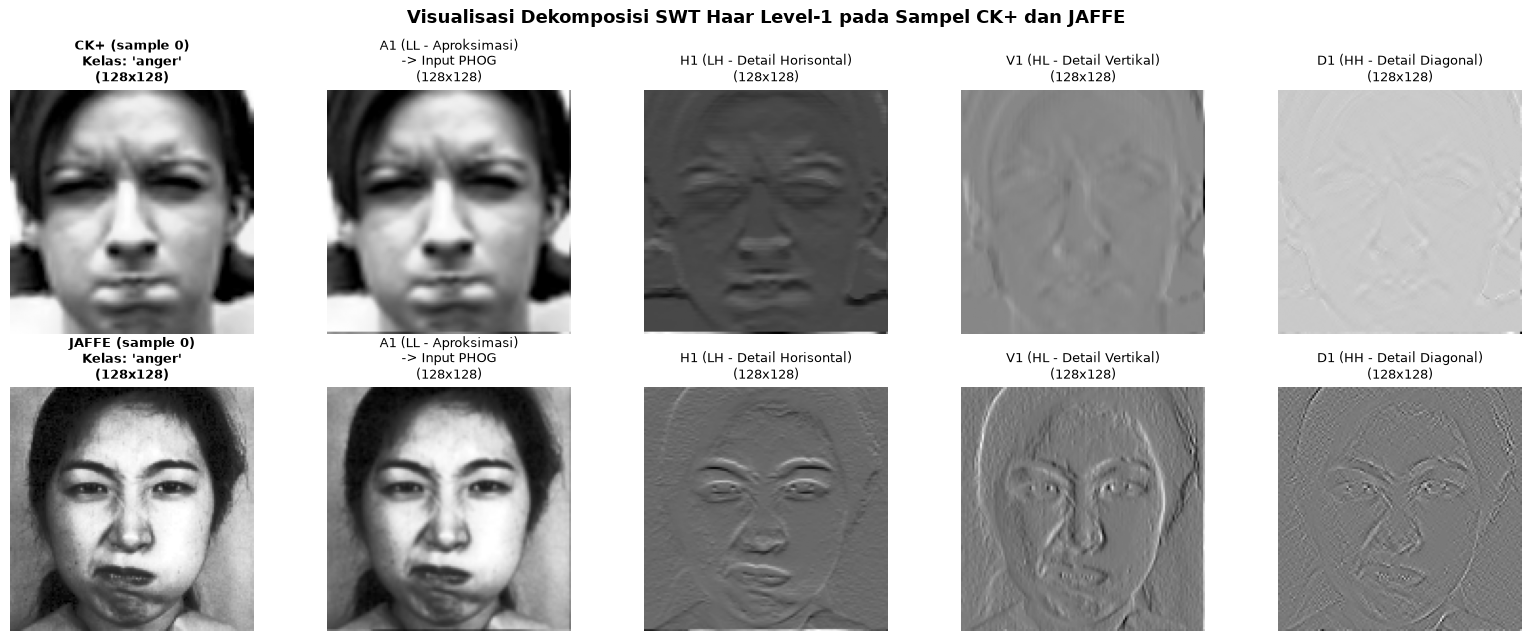

Verifikasi Dimensi Subband:
  Subband A1: bentuk (128, 128), dtype float64, min=0.0, maks=510.0
  Subband H1: bentuk (128, 128), dtype float64, min=-90.5, maks=230.0
  Subband V1: bentuk (128, 128), dtype float64, min=-255.0, maks=225.0
  Subband D1: bentuk (128, 128), dtype float64, min=-114.5, maks=30.5


In [3]:
# Ambil 1 sampel dari CK+ dan 1 sampel dari JAFFE
sample_ck = X_ck[0]
sample_jf = X_jf[0]

sub_ck = swt_haar_level1(sample_ck)
sub_jf = swt_haar_level1(sample_jf)

fig, axes = plt.subplots(2, 5, figsize=(16, 6.5))
datasets_demo = [
    ("CK+ (sample 0)", sample_ck, sub_ck, classes_ck[y_ck[0]]),
    ("JAFFE (sample 0)", sample_jf, sub_jf, classes_jf[y_jf[0]]),
]

for row, (name, orig, sub, label) in enumerate(datasets_demo):
    axes[row, 0].imshow(orig, cmap="gray")
    axes[row, 0].set_title(f"{name}\nKelas: '{label}'\n(128x128)", fontsize=9.5, fontweight="bold")
    axes[row, 0].axis("off")
    
    for col, (sub_name, title_desc) in enumerate([
        ("A1", "A1 (LL - Aproksimasi)\n-> Input PHOG"),
        ("H1", "H1 (LH - Detail Horisontal)"),
        ("V1", "V1 (HL - Detail Vertikal)"),
        ("D1", "D1 (HH - Detail Diagonal)"),
    ], start=1):
        axes[row, col].imshow(sub[sub_name], cmap="gray")
        axes[row, col].set_title(f"{title_desc}\n(128x128)", fontsize=9)
        axes[row, col].axis("off")

plt.suptitle("Visualisasi Dekomposisi SWT Haar Level-1 pada Sampel CK+ dan JAFFE", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

print("Verifikasi Dimensi Subband:")
for k, v in sub_ck.items():
    print(f"  Subband {k}: bentuk {v.shape}, dtype {v.dtype}, min={v.min():.1f}, maks={v.max():.1f}")


## 4. Landasan Teori: PHOG pada Subband A1 (§4.2.2 & §5.1, hal. 1475, 1478)

### Parameter Spesifikasi Jurnal:
1. **Tingkat Piramida $L = 3$**:
   - Level 0: membagi citra ke dalam $2^0 \times 2^0 = 1$ sel spasial (seluruh citra)
   - Level 1: membagi citra ke dalam $2^1 \times 2^1 = 4$ sel spasial
   - Level 2: membagi citra ke dalam $2^2 \times 2^2 = 16$ sel spasial
   - Level 3: membagi citra ke dalam $2^3 \times 2^3 = 64$ sel spasial
   $$\text{Total Sel} = \sum_{l=0}^{3} 4^l = 1 + 4 + 16 + 64 = 85 \text{ sel}$$

2. **Jumlah Bin Orientasi $K = 8$**:
   - Rentang sudut penuh $[0 - 360^\circ]$ (lebar tiap bin orientasi = $360^\circ / 8 = 45^\circ$).
   - Tiap piksel mengkontribusikan **magnitudo gradien** Sobel ke bin orientasinya.

3. **Dimensi Vektor Fitur Final**:
   $$F_{vz} = K \times \sum_{l=0}^{L} 4^l = 8 \times 85 = 680 \text{ dimensi}$$

4. **Skema Normalisasi**:
   - Jurnal: *"further normalised considering all the pyramid levels"*.
   - Kami menggunakan **Normalisasi $L_2$ per level piramida** ($v_l / \|v_l\|_2$) lalu digabungkan menjadi vektor 680-D. Ini mencegah level 3 (yang memiliki 64 sel) mendominasi level 0 (1 sel) sebelum tahap proyeksi LDA di A3.


C:\Users\luvma\AppData\Local\Temp\ipykernel_8196\2693766148.py:68: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


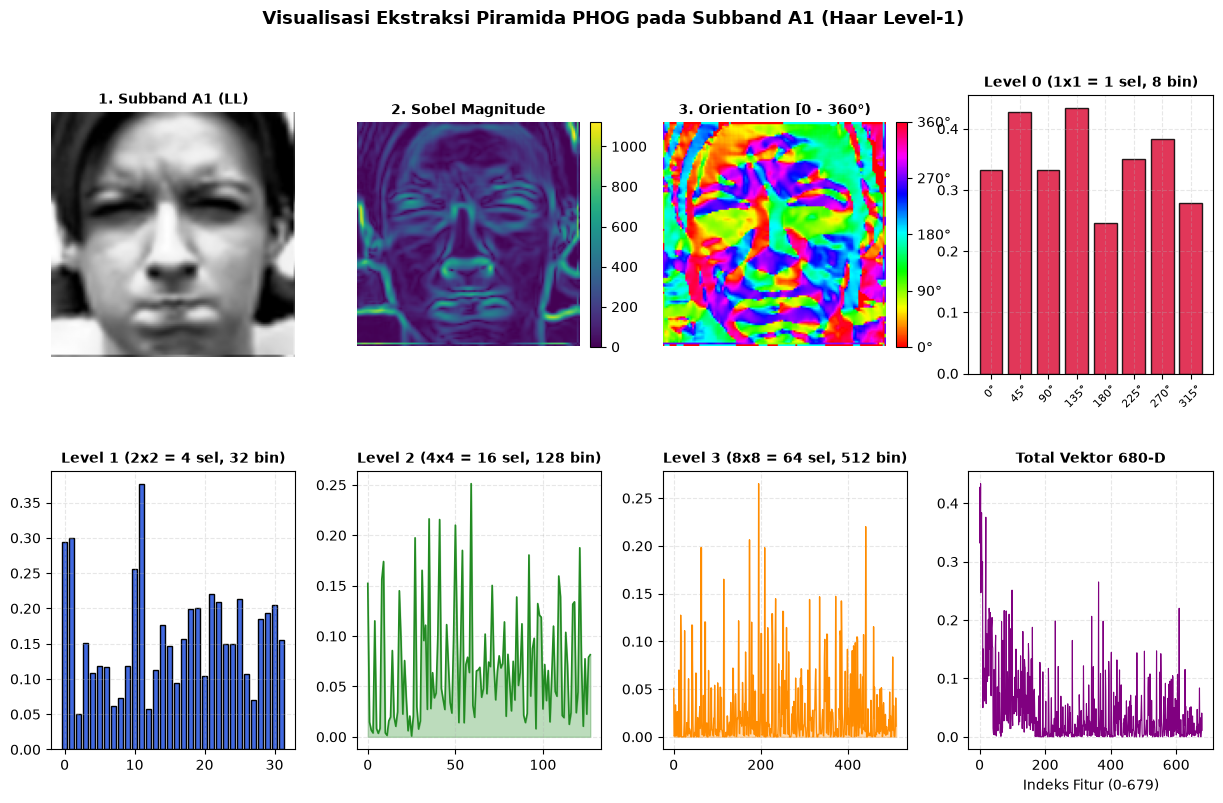

In [4]:
# Visualisasi alur PHOG pada subband A1 dari citra sampel CK+
a1_demo = sub_ck["A1"]
mag, ang = compute_gradients(a1_demo)
feat_demo = phog(a1_demo, L=3, K=8, norm="per_level")

fig = plt.figure(figsize=(15, 8.5))
gs = fig.add_gridspec(2, 4, hspace=0.35, wspace=0.25)

# 1. Subband A1
ax1 = fig.add_subplot(gs[0, 0])
ax1.imshow(a1_demo, cmap="gray")
ax1.set_title("1. Subband A1 (LL)", fontweight="bold", fontsize=10)
ax1.axis("off")

# 2. Gradient Magnitude
ax2 = fig.add_subplot(gs[0, 1])
im2 = ax2.imshow(mag, cmap="viridis")
ax2.set_title("2. Sobel Magnitude", fontweight="bold", fontsize=10)
ax2.axis("off")
plt.colorbar(im2, ax=ax2, fraction=0.046, pad=0.04)

# 3. Gradient Orientation [0 - 360)
ax3 = fig.add_subplot(gs[0, 2])
im3 = ax3.imshow(ang, cmap="hsv", vmin=0, vmax=360)
ax3.set_title("3. Orientation [0 - 360°)", fontweight="bold", fontsize=10)
ax3.axis("off")
cb3 = plt.colorbar(im3, ax=ax3, fraction=0.046, pad=0.04)
cb3.set_ticks([0, 90, 180, 270, 360])
cb3.set_ticklabels(["0°", "90°", "180°", "270°", "360°"])

# 4. Histogram Level 0 (1 cell x 8 bins)
ax4 = fig.add_subplot(gs[0, 3])
bin_labels = ["0°", "45°", "90°", "135°", "180°", "225°", "270°", "315°"]
ax4.bar(range(8), feat_demo[0:8], color="crimson", edgecolor="black", alpha=0.85)
ax4.set_xticks(range(8))
ax4.set_xticklabels(bin_labels, rotation=45, fontsize=8)
ax4.set_title("Level 0 (1x1 = 1 sel, 8 bin)", fontweight="bold", fontsize=10)
ax4.grid(True, linestyle="--", alpha=0.3)

# 5. Histogram Level 1 (4 cells x 8 = 32 bins)
ax5 = fig.add_subplot(gs[1, 0])
ax5.bar(range(32), feat_demo[8:40], color="royalblue", edgecolor="black", width=0.8)
ax5.set_title("Level 1 (2x2 = 4 sel, 32 bin)", fontweight="bold", fontsize=10)
ax5.grid(True, linestyle="--", alpha=0.3)

# 6. Histogram Level 2 (16 cells x 8 = 128 bins)
ax6 = fig.add_subplot(gs[1, 1])
ax6.plot(range(128), feat_demo[40:168], color="forestgreen", lw=1.2)
ax6.fill_between(range(128), feat_demo[40:168], color="forestgreen", alpha=0.3)
ax6.set_title("Level 2 (4x4 = 16 sel, 128 bin)", fontweight="bold", fontsize=10)
ax6.grid(True, linestyle="--", alpha=0.3)

# 7. Histogram Level 3 (64 cells x 8 = 512 bins)
ax7 = fig.add_subplot(gs[1, 2])
ax7.plot(range(512), feat_demo[168:680], color="darkorange", lw=0.9)
ax7.fill_between(range(512), feat_demo[168:680], color="darkorange", alpha=0.3)
ax7.set_title("Level 3 (8x8 = 64 sel, 512 bin)", fontweight="bold", fontsize=10)
ax7.grid(True, linestyle="--", alpha=0.3)

# 8. Profil Lengkap Vektor 680-D
ax8 = fig.add_subplot(gs[1, 3])
ax8.plot(feat_demo, color="purple", lw=0.8)
ax8.set_title("Total Vektor 680-D", fontweight="bold", fontsize=10)
ax8.set_xlabel("Indeks Fitur (0-679)")
ax8.grid(True, linestyle="--", alpha=0.3)

plt.suptitle("Visualisasi Ekstraksi Piramida PHOG pada Subband A1 (Haar Level-1)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()


## 5. Ekstraksi Fitur Seluruh Dataset (CK+ & JAFFE)

Kita mengekstraksi seluruh 981 citra CK+ dan 213 citra JAFFE menggunakan fungsi modular `extract_features(X)`. Fungsi ini mengeksekusi pipeline hybrid secara tervektorisasi:
$$\text{Citra } I_i \xrightarrow{\text{SWT Haar}} A_{1,i} \xrightarrow{\text{PHOG}} F_i \in \mathbb{R}^{680}$$


In [5]:
print(f"Memulai ekstraksi fitur seluruh sampel CK+ ({len(X_ck)} citra)...")
t0_ck = time.perf_counter()
F_ck = extract_features(X_ck, L=3, K=8, norm="per_level")
t1_ck = time.perf_counter()
waktu_ck = t1_ck - t0_ck
print(f"✓ Selesai ekstraksi CK+: {F_ck.shape} dalam {waktu_ck:.2f} detik ({(waktu_ck/len(X_ck))*1000:.2f} ms/citra)")

print(f"\nMemulai ekstraksi fitur seluruh sampel JAFFE ({len(X_jf)} citra)...")
t0_jf = time.perf_counter()
F_jaffe = extract_features(X_jf, L=3, K=8, norm="per_level")
t1_jf = time.perf_counter()
waktu_jf = t1_jf - t0_jf
print(f"✓ Selesai ekstraksi JAFFE: {F_jaffe.shape} dalam {waktu_jf:.2f} detik ({(waktu_jf/len(X_jf))*1000:.2f} ms/citra)")


Memulai ekstraksi fitur seluruh sampel CK+ (981 citra)...


✓ Selesai ekstraksi CK+: (981, 680) dalam 3.47 detik (3.54 ms/citra)

Memulai ekstraksi fitur seluruh sampel JAFFE (213 citra)...


✓ Selesai ekstraksi JAFFE: (213, 680) dalam 0.77 detik (3.61 ms/citra)


## 6. Verifikasi Wajib (Sel Assert)

Sesuai spesifikasi penugasan A2, kode harus memenuhi pengujian assert berikut:
```python
assert F_ck.shape    == (981, 680)
assert F_jaffe.shape == (213, 680)
assert np.isfinite(F_ck).all() and np.isfinite(F_jaffe).all()
```


In [6]:
# --- SEL VERIFIKASI WAJIB PENUGASAN A2 ---
assert F_ck.shape    == (981, 680), f"Bentuk CK+ salah: {F_ck.shape}"
assert F_jaffe.shape == (213, 680), f"Bentuk JAFFE salah: {F_jaffe.shape}"
assert np.isfinite(F_ck).all() and np.isfinite(F_jaffe).all(), "Ditemukan nilai non-finite (NaN / Inf)!"

print("=" * 65)
print(">>> HASIL: SELURUH ASSERT VERIFIKASI WAJIB LULUS 100%! <<<")
print("=" * 65)
print(f"✓ Bentuk matriks fitur CK+   : {F_ck.shape} (dtype: {F_ck.dtype})")
print(f"✓ Bentuk matriks fitur JAFFE : {F_jaffe.shape} (dtype: {F_jaffe.dtype})")
print(f"✓ Integritas numerik CK+     : finite={np.isfinite(F_ck).all()}, NaN={np.isnan(F_ck).any()}")
print(f"✓ Integritas numerik JAFFE   : finite={np.isfinite(F_jaffe).all()}, NaN={np.isnan(F_jaffe).any()}")
print(f"✓ Rentang nilai fitur CK+    : [{F_ck.min():.4f}, {F_ck.max():.4f}]")
print(f"✓ Rentang nilai fitur JAFFE  : [{F_jaffe.min():.4f}, {F_jaffe.max():.4f}]")


>>> HASIL: SELURUH ASSERT VERIFIKASI WAJIB LULUS 100%! <<<
✓ Bentuk matriks fitur CK+   : (981, 680) (dtype: float32)
✓ Bentuk matriks fitur JAFFE : (213, 680) (dtype: float32)
✓ Integritas numerik CK+     : finite=True, NaN=False
✓ Integritas numerik JAFFE   : finite=True, NaN=False
✓ Rentang nilai fitur CK+    : [0.0000, 0.5268]
✓ Rentang nilai fitur JAFFE  : [0.0000, 0.5279]


## 7. Analisis Statistik Fitur

Menganalisis karakteristik fitur gabungan (panjang, sparsity, persebaran nilai, dan komparasi ekspresi wajah):


--- Statistik Fitur ---
CK+   -> Rerata: 0.0418, Std: 0.0643, Sparsity (nilai nol): 5.64%
JAFFE -> Rerata: 0.0431, Std: 0.0634, Sparsity (nilai nol): 1.22%


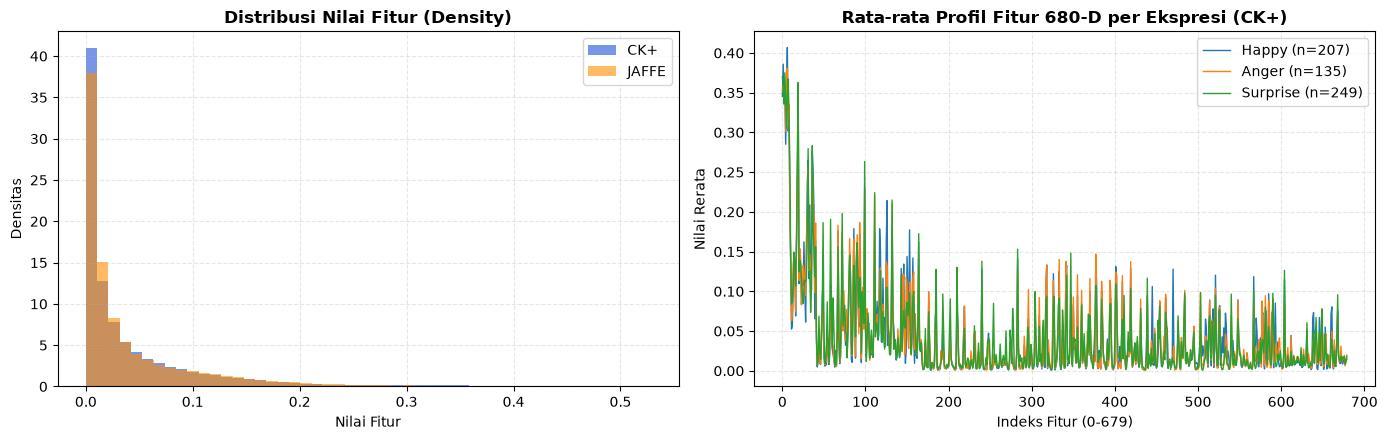

In [7]:
# 1. Analisis Sparsity (Persentase elemen nol)
zero_ck = np.mean(F_ck == 0.0) * 100.0
zero_jf = np.mean(F_jaffe == 0.0) * 100.0

print("--- Statistik Fitur ---")
print(f"CK+   -> Rerata: {F_ck.mean():.4f}, Std: {F_ck.std():.4f}, Sparsity (nilai nol): {zero_ck:.2f}%")
print(f"JAFFE -> Rerata: {F_jaffe.mean():.4f}, Std: {F_jaffe.std():.4f}, Sparsity (nilai nol): {zero_jf:.2f}%")

# 2. Plot Distribusi Nilai Fitur & Komparasi Antar-Ekspresi
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Distribusi nilai
axes[0].hist(F_ck.ravel(), bins=50, color="royalblue", alpha=0.7, label="CK+", density=True)
axes[0].hist(F_jaffe.ravel(), bins=50, color="darkorange", alpha=0.6, label="JAFFE", density=True)
axes[0].set_title("Distribusi Nilai Fitur (Density)", fontweight="bold")
axes[0].set_xlabel("Nilai Fitur")
axes[0].set_ylabel("Densitas")
axes[0].legend()
axes[0].grid(True, linestyle="--", alpha=0.3)

# Rata-rata profil fitur untuk 3 ekspresi berbeda di CK+
selected_classes = ["happy", "anger", "surprise"]
for cls_name in selected_classes:
    cls_idx = classes_ck.index(cls_name)
    mask = (y_ck == cls_idx)
    mean_profile = F_ck[mask].mean(axis=0)
    axes[1].plot(mean_profile, label=f"{cls_name.capitalize()} (n={mask.sum()})", lw=1.0)

axes[1].set_title("Rata-rata Profil Fitur 680-D per Ekspresi (CK+)", fontweight="bold")
axes[1].set_xlabel("Indeks Fitur (0-679)")
axes[1].set_ylabel("Nilai Rerata")
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()


## 8. Menyimpan Artefak Fitur untuk Anggota 3 (A3)

Menyimpan matriks fitur hasil ekstraksi ke folder `data/`:
- `data/ck_features.npz`
- `data/jaffe_features.npz`

Artefak berisi:
- `F`: matriks fitur `(N, 680)` bertipe `float32`
- `y`: label integer `(N,)`
- `subjects`: kode subjek `(N,)` untuk validasi subject-independent
- `class_names`: nama kelas urut alfabet


In [8]:
out_ck_path = repo_root / "data" / "ck_features.npz"
out_jf_path = repo_root / "data" / "jaffe_features.npz"

np.savez_compressed(
    out_ck_path,
    F=F_ck,
    y=y_ck,
    subjects=subjects_ck,
    class_names=np.array(classes_ck),
)
print(f"✓ Artefak CK+ berhasil disimpan di: {out_ck_path} ({out_ck_path.stat().st_size / (1024*1024):.2f} MB)")

np.savez_compressed(
    out_jf_path,
    F=F_jaffe,
    y=y_jf,
    subjects=subjects_jf,
    class_names=np.array(classes_jf),
)
print(f"✓ Artefak JAFFE berhasil disimpan di: {out_jf_path} ({out_jf_path.stat().st_size / (1024*1024):.2f} MB)")


✓ Artefak CK+ berhasil disimpan di: C:\Sora Games\personal needs\KULIAH\SEMESTER 5\PCVK\2nd try\TA-PCVK\data\ck_features.npz (2.26 MB)
✓ Artefak JAFFE berhasil disimpan di: C:\Sora Games\personal needs\KULIAH\SEMESTER 5\PCVK\2nd try\TA-PCVK\data\jaffe_features.npz (0.51 MB)


## 9. Verifikasi Ulang Pembacaan Artefak Output

Memastikan file yang disimpan dapat dimuat kembali dengan sempurna oleh anggota A3 tanpa hambatan:

In [9]:
test_ck = np.load(out_ck_path)
test_jf = np.load(out_jf_path)

assert test_ck["F"].shape == (981, 680)
assert test_jf["F"].shape == (213, 680)
assert test_ck["F"].dtype == np.float32
assert test_jf["F"].dtype == np.float32
np.testing.assert_array_equal(test_ck["y"], y_ck)
np.testing.assert_array_equal(test_jf["y"], y_jf)

print("✓ Uji pembacaan artefak handoff ke A3 sukses!")
print(f"  - Keys CK+   : {test_ck.files}")
print(f"  - Keys JAFFE : {test_jf.files}")


✓ Uji pembacaan artefak handoff ke A3 sukses!
  - Keys CK+   : ['F', 'y', 'subjects', 'class_names']
  - Keys JAFFE : ['F', 'y', 'subjects', 'class_names']


## 10. Ringkasan & Handoff ke A3 (Model & Optimasi)

Tahap **Feature Engineering (A2)** telah selesai dikerjakan sesuai spesifikasi teknis jurnal Kar et al. (2021):

| Komponen | Spesifikasi Teknis | Hasil Implementasi |
|---|---|---|
| **Transformasi Wavelet** | SWT Haar Level-1 (shift-invariant, tanpa desimasi) | 4 subband $128\times 128$ ($A_1, H_1, V_1, D_1$) |
| **Subband Pilihan** | $A_1$ (Aproksimasi LL) | Sesuai Persamaan 3–4 jurnal |
| **Piramida PHOG** | $L=3$ (Level 0: 1, Level 1: 4, Level 2: 16, Level 3: 64 sel) | Total 85 sel spasial |
| **Orientasi Gradien** | $K=8$ bin dalam rentang $[0 - 360^\circ]$ | Sobel $3\times 3$ terbobot magnitudo |
| **Normalisasi** | $L_2$ per level piramida | Skala fitur seimbang per resolusi spasial |
| **Dimensi Fitur** | $85 \times 8 = 680$ fitur per citra | `(981, 680)` pada CK+ & `(213, 680)` pada JAFFE |
| **Integritas Numerik** | Bebas NaN dan Inf, tipe data `float32` | $100\%$ finite & valid |
| **Artefak Handoff** | Disimpan di folder `data/` | `ck_features.npz` & `jaffe_features.npz` |

### Langkah Selanjutnya untuk Anggota 3 (A3):
A3 dapat langsung memuat artefak ini untuk menjalankan:
1. Reduksi dimensi fitur dengan **LDA** ($680 \to 7$ fitur untuk CK+, $680 \to 6$ fitur untuk JAFFE).
2. Pelatihan dan tuning parameter $(C, \sigma)$ pada classifier **LS-SVM** menggunakan algoritma metaheuristik **Jaya** (JOLS-SVM).
3. Evaluasi performa dengan **5-fold stratified cross-validation**.
